In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

# For saving the state of the graph to memory, stores the memory in the RAM.
from langgraph.checkpoint.memory import MemorySaver

In [2]:
load_dotenv()

True

In [3]:
llm = ChatOpenAI(model="gpt-5.6-terra")

In [4]:
from langgraph.graph.message import add_messages

# State is something that is passed to the graph and 
# can be used to store information about the current state of the conversation.


class ChatState(TypedDict): 
    messages: Annotated[list[BaseMessage], add_messages] # Using reducer for 'messages' to add 'messages' to the state.

In [5]:
# Creating chat node function that takes the state as 
# input and returns the updated state with the response from the LLM.

def chat_node(state: ChatState):
    #take user query from state
    messages = state['messages']
    # send to llm
    response = llm.invoke(messages)
    # response store state
    return {'messages': [response]}

In [6]:
graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node) # Only one node is required for this simple chatbot.

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

# Compile the graph.
chatbot = graph.compile()

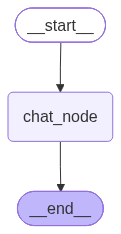

In [7]:
chatbot

In [8]:
initial_state = {
    'messages': [HumanMessage(content='What is OOPs in python?')]
}

response = chatbot.invoke(initial_state)

In [9]:
response['messages'][-1].content

'OOPs in Python means **Object-Oriented Programming**. It is a programming style where code is organized using **objects** and **classes**.\n\n- A **class** is a blueprint/template.\n- An **object** is an instance created from that class.\n\nFor example, a `Car` class can describe common properties and behaviors of cars. Individual cars such as a BMW or Tesla are objects.\n\n```python\nclass Car:\n    def __init__(self, brand, color):\n        self.brand = brand\n        self.color = color\n\n    def start(self):\n        print(f"{self.brand} car is starting.")\n\ncar1 = Car("Tesla", "Red")\ncar1.start()\n```\n\nOutput:\n\n```text\nTesla car is starting.\n```\n\nHere:\n\n- `Car` is a class.\n- `car1` is an object.\n- `brand` and `color` are attributes (data).\n- `start()` is a method (behavior).\n- `__init__()` is a constructor, called automatically when an object is created.\n- `self` refers to the current object.\n\n## Main OOP concepts in Python\n\n### 1. Encapsulation\nCombining da

In [10]:
while True:
    user_message = input('Type here: ')

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]})
    print('AI:', response['messages'][-1].content)

User: Hi
AI: Hi! How can I help?
User: what is your name ?
AI: I’m ChatGPT.
User: remember my name is Arpan
AI: Got it, Arpan.
User: what is my name ?
AI: I don’t know your name—you haven’t told me yet.
User: 
AI: How can I help you today?
User: bye


## Still it cannot give me my info as I have shared my name before in the conversation, cause Persistent memory is not implemented yet. So, I will implement it in the next step.

In [11]:
checkpoint = MemorySaver() # Persistence of the state of the graph to memory, stores the memory in the RAM.

graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node) # Only one node is required for this simple chatbot.

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

# Compile the graph.
chatbot = graph.compile(checkpointer=checkpoint) # Compile the graph with the checkpoint to save the state of the graph to memory.

In [12]:
thread_id = "1"

while True:
    user_message = input('Type here: ')

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break
    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)
    print('AI:', response['messages'][-1].content)

User: Hi
AI: Hi! How can I help?
User: my name is Arpan
AI: Nice to meet you, Arpan! How can I help today?
User: what is your name ?
AI: I’m ChatGPT. You can call me ChatGPT or give me a nickname if you’d like.
User: what is my name ?
AI: Your name is Arpan.
User: bye


In [13]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='d39d04f2-dd02-42da-99dc-195df8f6fe3b'), AIMessage(content='Hi! How can I help?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 7, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-terra', 'system_fingerprint': None, 'id': 'chatcmpl-EhIShsuqIpsvdf3njauQBUc3MhQLh', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1b201-1928-7112-82e2-835c9175f900-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 7, 'output_tokens': 10, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_